In [1]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import cifar10
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from sklearn.metrics import confusion_matrix
import seaborn as sns
import pandas as pd
from ipywidgets import interact_manual

#資料預處理

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 786s 5us/step
訓練資料形狀:(50000, 32, 32, 3), 訓練答案形狀:(50000, 1)
測試資料形狀:(10000, 32, 32, 3), 測試答案形狀:(10000, 1)


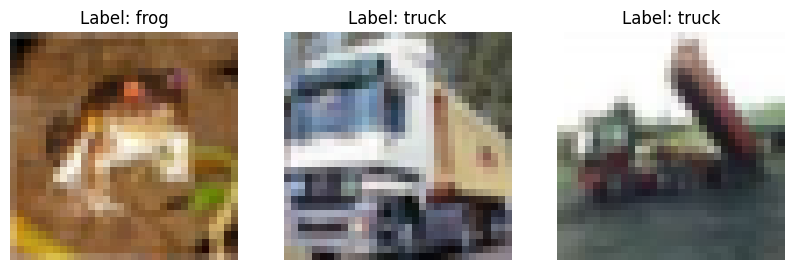

In [2]:
(x_train, y_train), (x_test, y_test) = cifar10.load_data()
print(f"訓練資料形狀:{x_train.shape}, 訓練答案形狀:{y_train.shape}")
print(f"測試資料形狀:{x_test.shape}, 測試答案形狀:{y_test.shape}")
#正規化
x_Train= x_train.astype("float32") /255.0
x_Test= x_test.astype("float32") /255.0

#One-hot編碼
y_train_onehot = to_categorical(y_train, 10)
y_test_onehot = to_categorical(y_test, 10)

#訓練資料圖片、label名稱
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
plt.figure(figsize=(10, 3))
for i in range(3):
    plt.subplot(1, 3, i + 1)
    plt.imshow(x_train[i])
    label_idx = y_train[i][0]
    plt.title(f"Label: {class_names[label_idx]}")
    plt.axis('off')
plt.show()

#建立神經網路模型

In [3]:
model = Sequential([
  # 第1層：卷積層
  Conv2D(32, (3, 3), activation='relu', padding='same', input_shape=(32, 32, 3)),
  # input shape: (128, 32, 32, 3)
  # 第一卷積層 output shape: (128, 32, 32, 32)
  # 參數個數: (3*3*3+1)*32 = 896

  # 第2層：Dropout
  Dropout(0.3),
  # output shape: (128, 32, 32, 32)
  # 參數個數: 0

  # 第3層：卷積層
  Conv2D(32, (3, 3), activation='relu', padding='same'),
  # 第二卷積層 output shape: (128, 32, 32, 32)
  # 參數個數: (3*3*32+1)*32 = 9248

  # 第4層：池化層
  MaxPooling2D((2, 2)),
  # 第一池化層 output shape: (128, 16, 16, 32)
  # 參數個數: 0

  # 第5層：卷積層
  Conv2D(64, (3, 3), activation='relu', padding='same'),
  # 第三卷積層 output shape: (128, 16, 16, 64)
  # 參數個數: (3*3*32+1)*64 = 18496

  # 第6層：Dropout
  Dropout(0.3),
  # output shape: (128, 16, 16, 64)
  # 參數個數: 0

  # 第7層：卷積層
  Conv2D(64, (3, 3), activation='relu', padding='same'),
  # 第四卷積層 output shape: (128, 16, 16, 64)
  # 參數個數: (3*3*64+1)*64 = 36928

  # 第8層：池化層
  MaxPooling2D((2, 2)),
  # 第二池化層 output shape: (128, 8, 8, 64)
  # 參數個數: 0

  # 第9層：卷積層
  Conv2D(128, (3, 3), activation='relu', padding='same'),
  # 第五卷積層 output shape: (128, 8, 8, 128)
  # 參數個數: (3*3*64+1)*128 = 73856

  # 第10層：Dropout
  Dropout(0.3),
  # output shape: (128, 8, 8, 128)
  # 參數個數: 0

  # 第11層：卷積層
  Conv2D(128, (3, 3), activation='relu', padding='same'),
  # 第六卷積層 output shape: (128, 8, 8, 128)
  # 參數個數: (3*3*128+1)*128 = 147584

  # 第12層：池化層
  MaxPooling2D((2, 2)),
  # 第三池化層 output shape: (128, 4, 4, 128)
  # 參數個數: 0

  # 第13層：拉平層
  Flatten(),
  # output shape: (128, 2048)
  # 參數個數: 0

  # 第14層：Dropout
  Dropout(0.3),
  # output shape: (128, 2048)
  # 參數個數: 0

  # 第15層：全連接層
  Dense(2500, activation='relu'),
  # output shape: (128, 2500)
  # 參數個數: (2048+1)*2500 = 5122500

  # 第16層：Dropout
  Dropout(0.3),
  # output shape: (128, 2500)
  # 參數個數: 0

  # 第17層：全連接層
  Dense(1500, activation='relu'),
  # output shape: (128, 1500)
  # 參數個數: (2500+1)*1500 = 3751500

  # 第18層：Dropout
  Dropout(0.3),
  # output shape: (128, 1500)
  # 參數個數: 0

  # 第19層：輸出層
  Dense(10, activation='softmax')
  # output shape: (128, 10)
  # 參數個數: (1500+1)*10 = 15010
])

model.summary()
                #hw4-3跟hw4-2的比較
      #1防止過擬合效果更強、2訓練出來的結果更準了、3訓練時間變長

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 8, 8, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 2500)           │     5,122,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 2500)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1500)           │     3,751,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 1500)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │        15,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,176,018 (35.00 MB)

 Trainable params: 9,176,018 (35.00 MB)

 Non-trainable params: 0 (0.00 B)

#訓練神經網路模型

In [4]:
#input shape: (128, 32, 32, 3)
#第一卷積層output shape: (128, 32, 32, 32)
#參數個數: (3*3*3+1)*32 = 896
#第一池化層output shape: (128, 16, 16, 32)
#參數個數: 0

#第二卷積層output shape: (128, 16, 16, 64)
#參數個數: (3*3*32+1)*64 = 18496

#第二池化層output shape: (128, 8, 8, 64)
#參數個數: 0

#第三卷積層output shape: (128, 8, 8, 64)
#參數個數: (3*3*64+1)*64 = 36928

#展平層output shape: (128,4096)
#參數個數:0

#全連接層output shape: (128,64)
#參數個數: (4096+1)*64=262208

#輸出層output shape: (128,10)
#參數個數: (64+1)*10=650


model.compile(loss='categorical_crossentropy',
      optimizer='adam',metrics=['accuracy'])

train_history = model.fit(x_Train, y_train_onehot,validation_split=0.2,
          epochs=50, batch_size=128)

Epoch 1/50
313/313 ━━━━━━━━━━━━━━━━━━━━ 353s 1s/step - accuracy: 0.3331 - loss: 1.7903 - val_accuracy: 0.4083 - val_loss: 1.6043
Epoch 2/50
313/313 ━━━━━━━━━━━━━━━━━━━━ 384s 1s/step - accuracy: 0.4998 - loss: 1.3674 - val_accuracy: 0.5426 - val_loss: 1.2515
Epoch 3/50
313/313 ━━━━━━━━━━━━━━━━━━━━ 345s 1s/step - accuracy: 0.5737 - loss: 1.1882 - val_accuracy: 0.5944 - val_loss: 1.1365
Epoch 4/50
313/313 ━━━━━━━━━━━━━━━━━━━━ 386s 1s/step - accuracy: 0.6207 - loss: 1.0619 - val_accuracy: 0.6386 - val_loss: 1.0118
Epoch 5/50
313/313 ━━━━━━━━━━━━━━━━━━━━ 354s 1s/step - accuracy: 0.6538 - loss: 0.9672 - val_accuracy: 0.6849 - val_loss: 0.9021
Epoch 6/50
313/313 ━━━━━━━━━━━━━━━━━━━━ 361s 1s/step - accuracy: 0.6854 - loss: 0.8921 - val_accuracy: 0.7006 - val_loss: 0.8579
Epoch 7/50
313/313 ━━━━━━━━━━━━━━━━━━━━ 365s 1s/step - accuracy: 0.7042 - loss: 0.8342 - val_accuracy: 0.7069 - val_loss: 0.8380
Epoch 8/50
313/313 ━━━━━━━━━━━━━━━━━━━━ 357s 1s/step - accuracy: 0.7266 - loss: 0.7743 - val_accu

#以折線圖顯示訓練過程

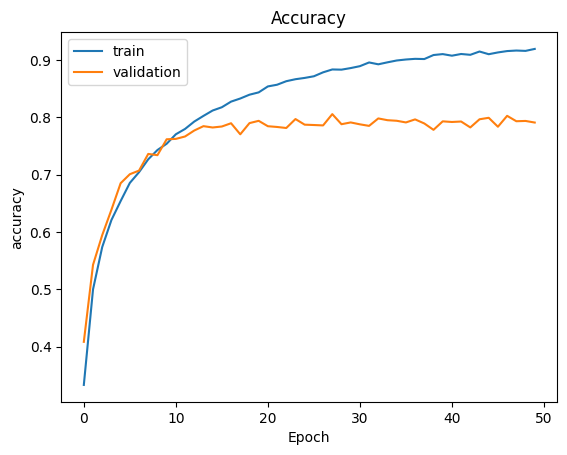

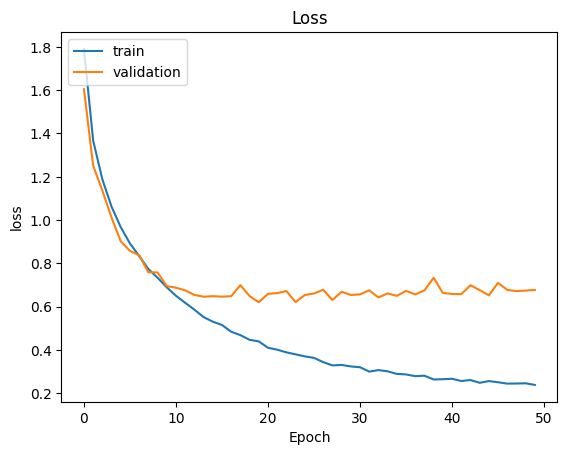

In [5]:
def show_train_history(name,train_history,train,validation):
    plt.plot(train_history.history[train])
    plt.plot(train_history.history[validation])
    plt.title(name)
    plt.ylabel(train)
    plt.xlabel('Epoch')
    plt.legend(['train', 'validation'], loc='upper left')
    plt.show()
#準確率
show_train_history("Accuracy",train_history,'accuracy','val_accuracy')
#損失誤差
show_train_history("Loss",train_history,'loss','val_loss')

#評估模型準確率

In [6]:
test_acc = model.evaluate(x_Test, y_test_onehot)
print(f"測試資料集準確率(Accuracy): {test_acc[1]}")

313/313 ━━━━━━━━━━━━━━━━━━━━ 23s 72ms/step - accuracy: 0.7810 - loss: 0.7219
測試資料集準確率(Accuracy): 0.781000018119812


#進行預測

313/313 ━━━━━━━━━━━━━━━━━━━━ 21s 67ms/step


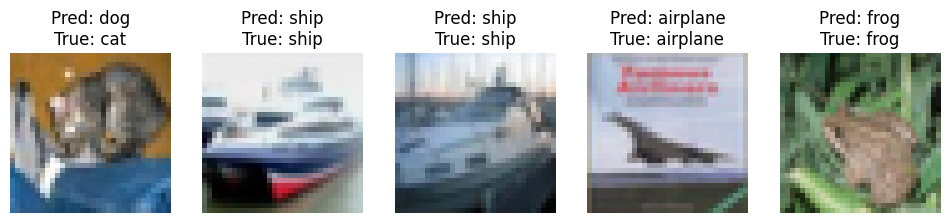

In [7]:
predictions = model.predict(x_Test)
pred_labels = np.argmax(predictions, axis=1)
true_labels = y_test.flatten()

plt.figure(figsize=(12, 4))
for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(x_test[i])
    p_name = class_names[pred_labels[i]]
    t_name = class_names[true_labels[i]]
    plt.title(f"Pred: {p_name}\nTrue: {t_name}")
    plt.axis('off')
plt.show()

#混淆矩陣呈現預測結果

In [8]:
prediction = np.argmax(model.predict(x_Test), axis=1)

y_test_names = [class_names[i] for i in y_test.flatten()]
prediction_names = [class_names[i] for i in prediction]

pd.crosstab(pd.Series(y_test_names, name='實際答案'),
            pd.Series(prediction_names, name='模型預測'))

313/313 ━━━━━━━━━━━━━━━━━━━━ 22s 70ms/step


模型預測,airplane,automobile,bird,cat,deer,dog,frog,horse,ship,truck
實際答案,,,,,,,,,,
airplane,824,9,44,21,7,9,10,10,58,8
automobile,6,897,4,10,5,8,8,1,12,49
bird,57,2,696,57,52,55,60,12,6,3
cat,12,1,71,617,40,152,71,26,7,3
deer,26,3,73,70,705,32,50,35,6,0
dog,7,0,39,177,29,694,30,23,1,0
frog,4,2,29,37,23,10,890,1,1,3
horse,6,1,37,47,53,46,4,802,1,3
ship,56,11,11,21,14,12,14,4,848,9


#儲存完整模型

In [9]:
model.save('hw4-1_cifar10_model.keras')

#測試圖片預測結果

In [10]:
def test_prediction(idx):
    plt.figure(figsize=(3, 3))
    plt.imshow(x_test[idx])
    plt.axis('off')
    plt.show()

    pred_class = class_names[pred_labels[idx]]
    true_class = class_names[true_labels[idx]]
    print(f"模型預測結果: {pred_class}")
    print(f"實際真實標籤: {true_class}")

interact_manual(test_prediction, idx=(0, len(x_test)-1))

interactive(children=(IntSlider(value=4999, description='idx', max=9999), Button(description='Run Interact', s…

<function __main__.test_prediction(idx)>